### Seaborn - 고급 그래프
: Matplotlib의 기능과 스타일을 확장한 파이썬 시각 도구의 고급 버전

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import koreanize_matplotlib

In [3]:
titanic = sns.load_dataset('titanic')
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


#### 회귀선이 있는 산점도
: 선형회귀분석에 의한 회귀선을 생성

In [4]:
# 스타일 테마(darkgrid, whitegrid, dark, white, ticks)
sns.set_style('darkgrid')

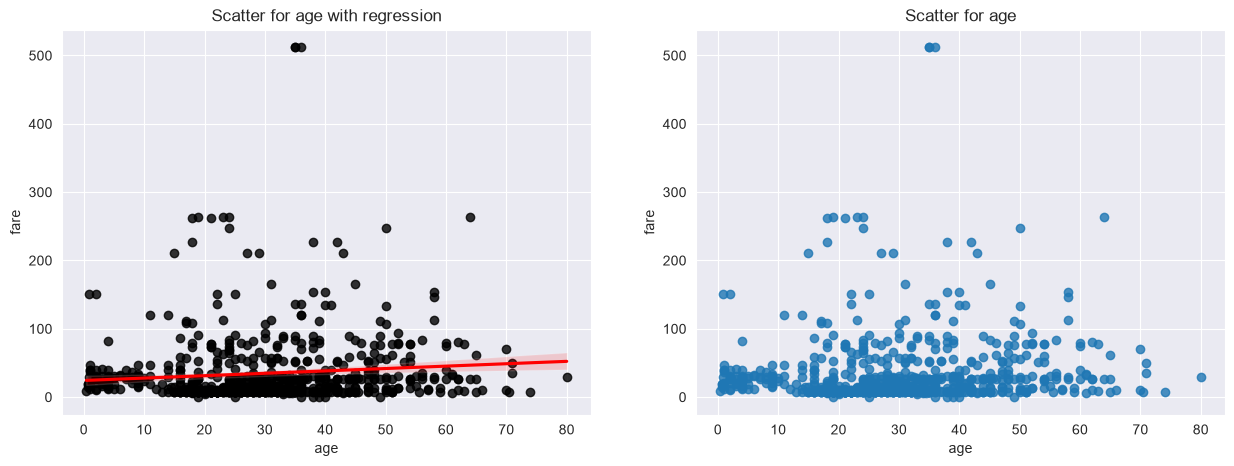

In [9]:
fig = plt.figure(figsize=(15,5))
ax1 = fig.add_subplot(1,2,1)
ax2 = fig.add_subplot(1,2,2)

sns.regplot(
    x='age',
    y='fare',
    data=titanic,
    scatter_kws={'color' : 'black'},
    line_kws={"color" : "red"},
    ax=ax1
)
sns.regplot(
    x='age',
    y='fare',
    data=titanic,
    # scatter_kws={'color' : 'black'},
    # line_kws={"color" : "red"},
    ax=ax2,
    fit_reg=False
)

ax1.set_title("Scatter for age with regression")
ax2.set_title("Scatter for age")

plt.show()

> 회귀선에 옅은 색의 범위는 오차범위

---
#### 히트맵(hearmap)

In [12]:
# 성별 객실별 승선 인원수
table = titanic.pivot_table(
    index=['sex'],
    columns=['class'],
    aggfunc='size'
)
table

class,First,Second,Third
sex,,,
female,94,76,144
male,122,108,347


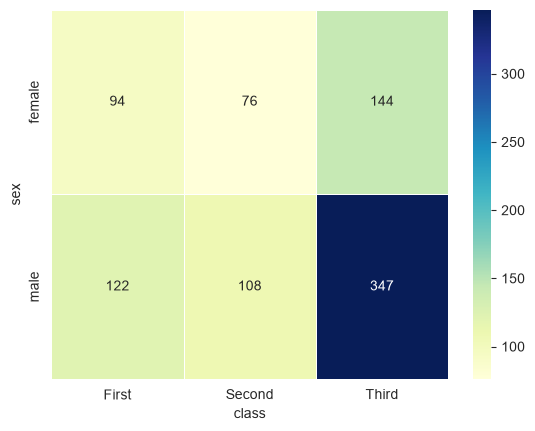

In [ ]:
sns.heatmap(
    table,
    annot=True,
    fmt='d',        # 숫자 변환 (ex: 1.4e+02 -> 144)
    cmap='YlGnBu',  # 색상 변경
    linewidths=.5
)
plt.show()

----
#### 데이터의 산점도

In [24]:
sns.set_style('whitegrid')

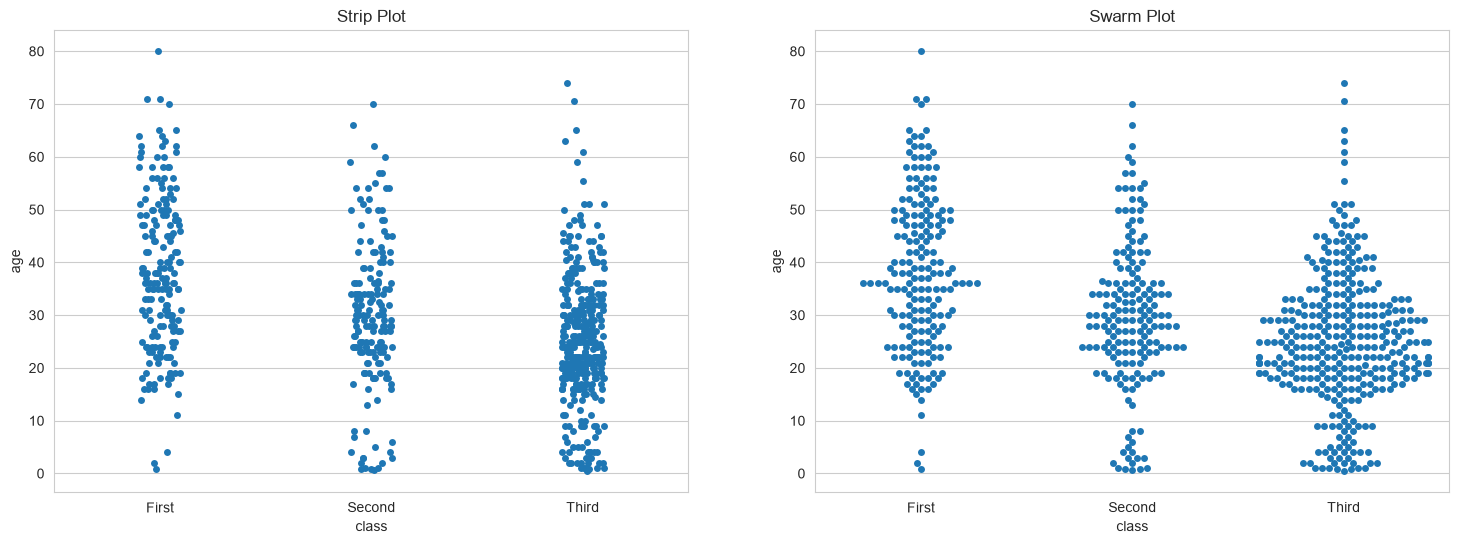

In [26]:
fig = plt.figure(figsize=(18,6))
ax1 = fig.add_subplot(1,2,1)
ax2 = fig.add_subplot(1,2,2)

# 데이터의 분산을 고려하지 않은 분포
sns.stripplot(
    x='class',
    y='age',
    data=titanic,
    ax=ax1
)
# 데이터의 분산을 고려한 분포
sns.swarmplot(
    x='class',
    y='age',
    data=titanic,
    ax=ax2
)

ax1.set_title('Strip Plot')
ax2.set_title('Swarm Plot')

plt.show()

---
#### 막대 그래프

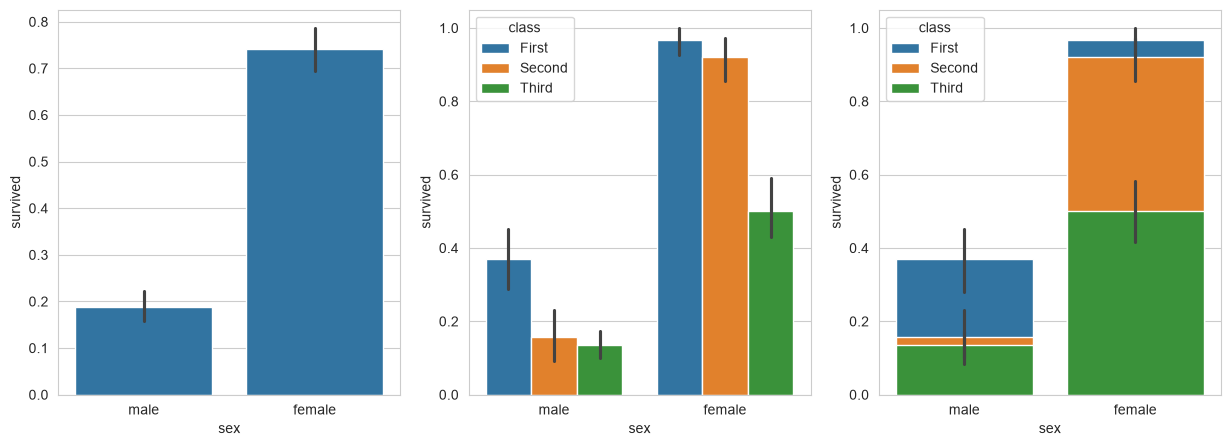

In [31]:
fig = plt.figure(figsize=(15,5))
ax1 = fig.add_subplot(1,3,1)
ax2 = fig.add_subplot(1,3,2)
ax3 = fig.add_subplot(1,3,3)

sns.barplot(
    x='sex',
    y='survived',
    data=titanic,
    ax=ax1
)
sns.barplot(
    x='sex',
    y='survived',
    hue='class',
    data=titanic,
    ax=ax2
)
sns.barplot(
    x='sex',
    y='survived',
    hue='class',
    data=titanic,
    dodge=False,
    ax=ax3
)

plt.show()

> 바 위에 있는 검은색 선은 오차막대

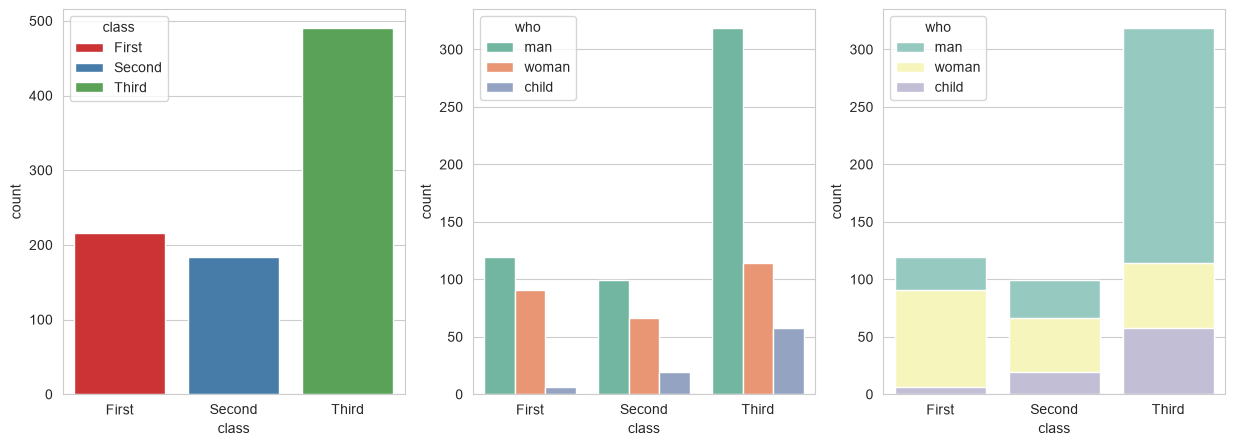

In [57]:
fig = plt.figure(figsize=(15,5))
ax1 = fig.add_subplot(1,3,1)
ax2 = fig.add_subplot(1,3,2)
ax3 = fig.add_subplot(1,3,3)

sns.countplot(
    x='class',
    hue='class',
    palette='Set1',
    data=titanic,
    ax=ax1,
    dodge=False,
    legend=True
)

sns.countplot(
    x='class',
    hue='who',
    palette='Set2',
    data=titanic,
    ax=ax2
)
sns.countplot(
    x='class',
    hue='who',
    palette='Set3',
    data=titanic,
    dodge=False,
    ax=ax3
)

plt.show()

---
#### 박스플롯/바이올린 그래프
: 박스플롯은 주요 통계 지표를 제공하지만 분산의 정도를 알 수가 없다.

<Axes: xlabel='alive', ylabel='age'>

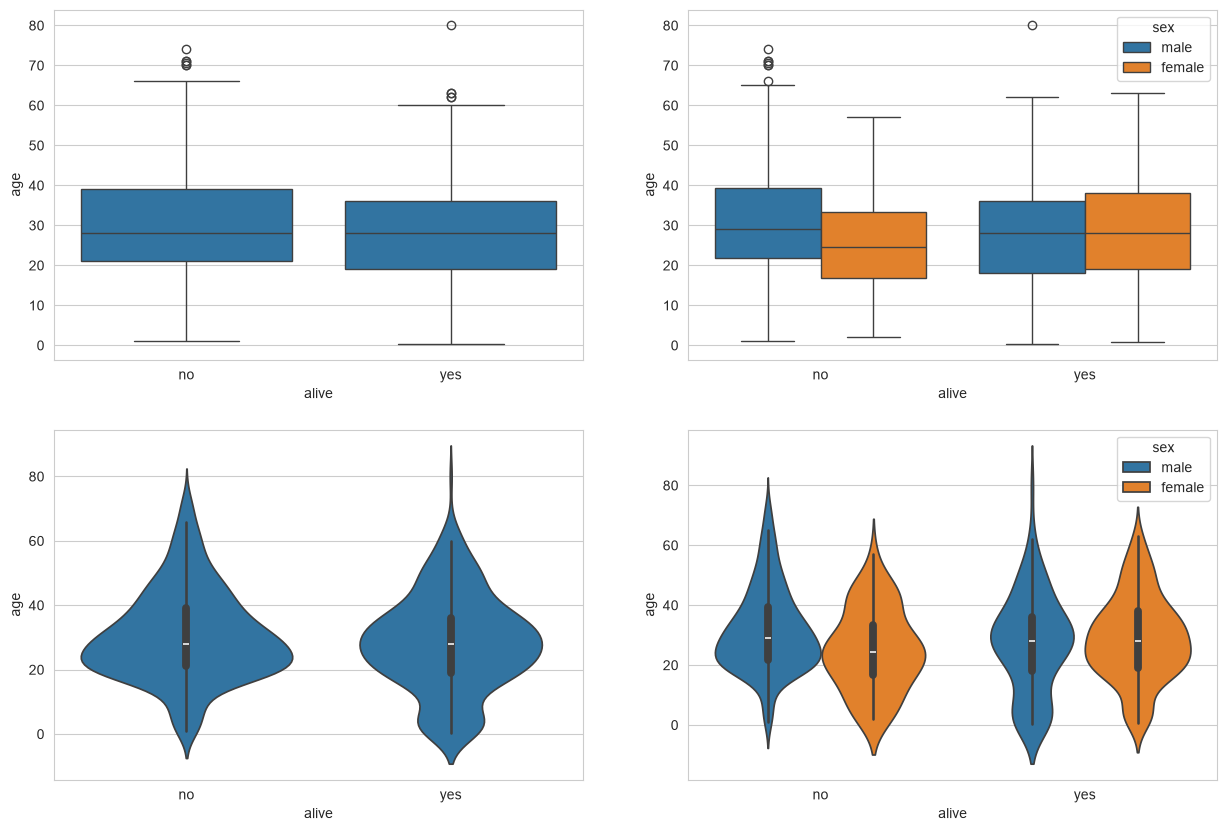

In [49]:
fig=plt.figure(figsize=(15, 10))
ax1 = fig.add_subplot(2,2,1)
ax2 = fig.add_subplot(2,2,2)
ax3 = fig.add_subplot(2,2,3)
ax4 = fig.add_subplot(2,2,4)

sns.boxplot(
    x='alive',
    y='age',
    data=titanic,
    ax=ax1
)

sns.boxplot(
    x='alive',
    y='age',
    hue='sex',
    data=titanic,
    ax=ax2
)

sns.violinplot(
    x='alive',
    y='age',
    data=titanic,
    ax=ax3
)

sns.violinplot(
    x='alive',
    y='age',
    hue='sex',
    data=titanic,
    ax=ax4
)

----
#### 조인트 그래프
: 산점도를 기본으로 표시하고 각 축에 대한 히스토그램을 동시 제공

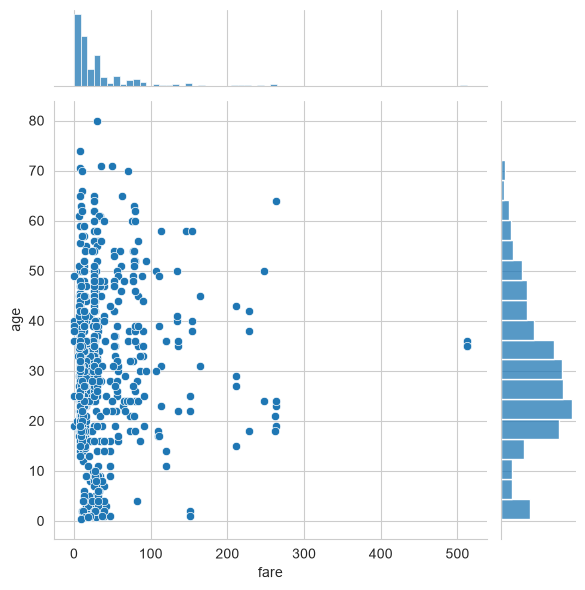

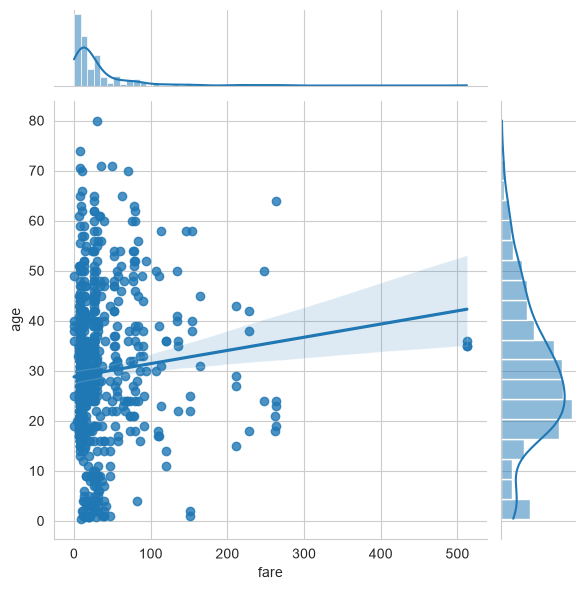

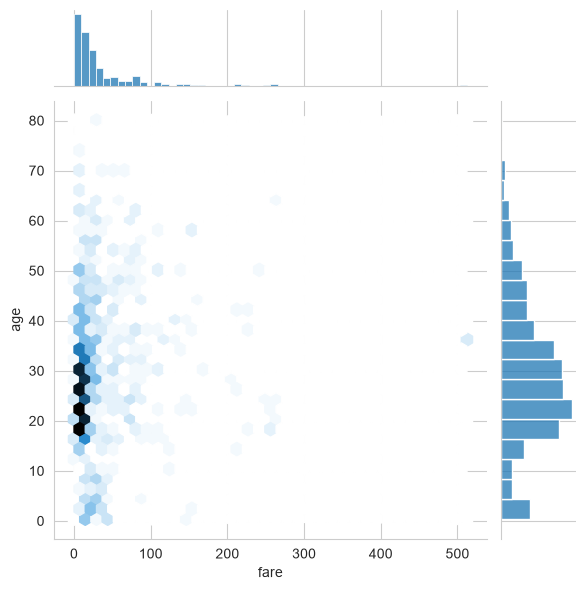

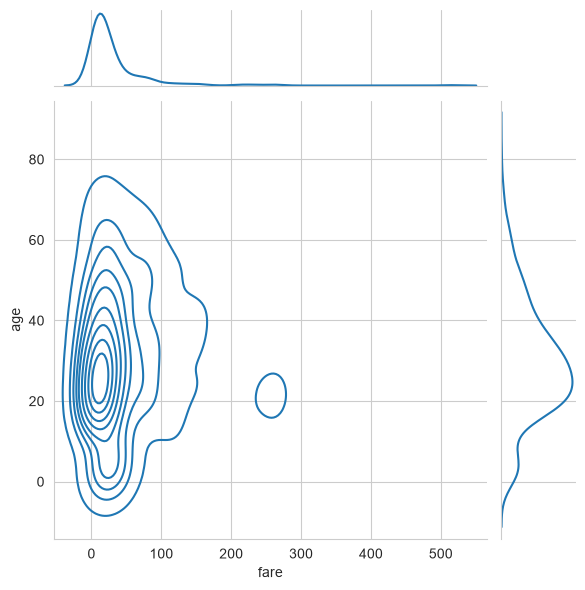

In [60]:
sns.jointplot(
    x='fare',
    y='age',
    data=titanic
)

sns.jointplot(
    x='fare',
    y='age',
    kind='reg',
    data=titanic
)

sns.jointplot(
    x='fare',
    y='age',
    kind='hex',
    data=titanic
)

sns.jointplot(
    x='fare',
    y='age',
    kind='kde',
    data=titanic
)

plt.show()

---
#### 조건을 적용하여 화면을 그리드로 분할하기

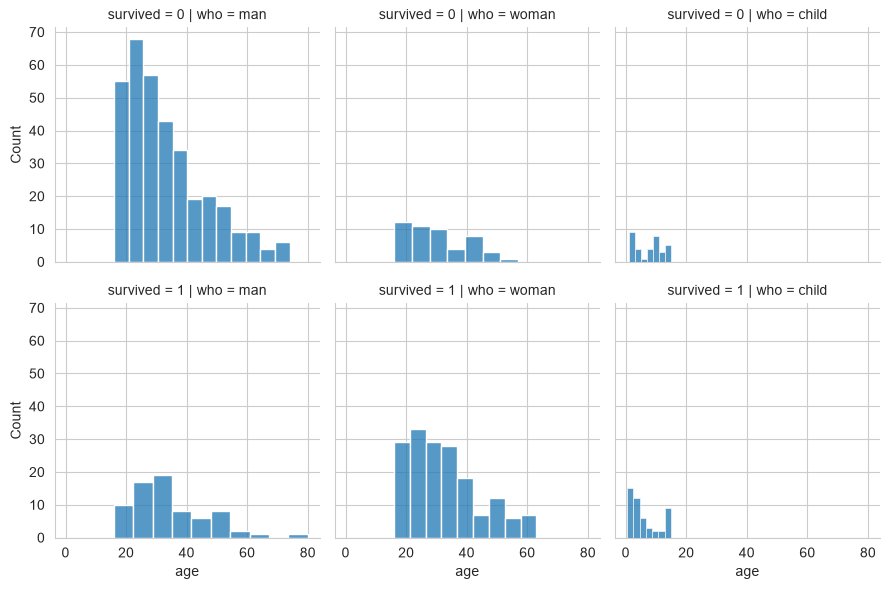

In [63]:
# 조건에 따라 그리드 나누기
g = sns.FacetGrid(
    data= titanic,
    col='who',
    row='survived'
)

# 그래프 적용
g.map_dataframe(sns.histplot, x='age')

plt.show()

---
#### 이변수 데이터의 분포

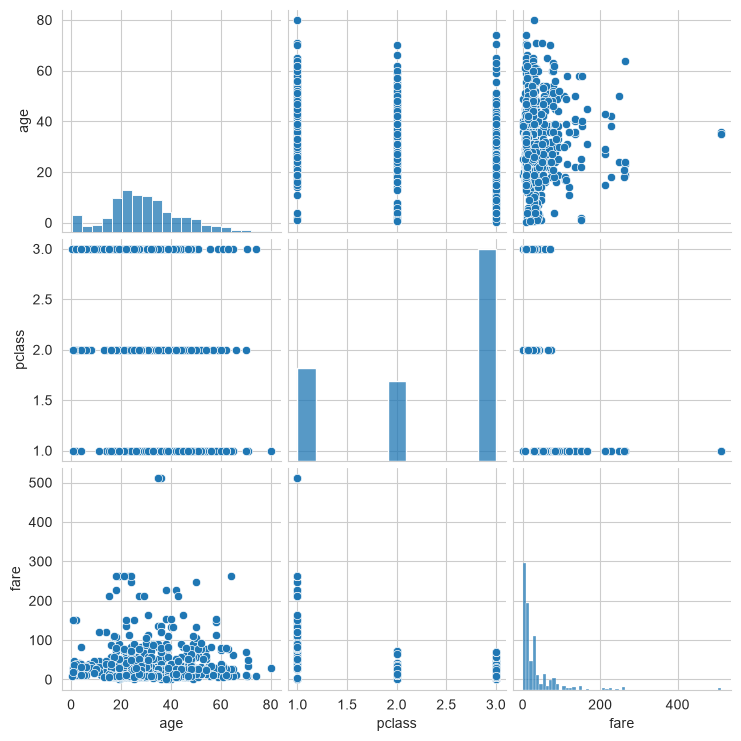

In [64]:
titanic_pair = titanic[['age', 'pclass', 'fare']]
sns.pairplot(titanic_pair)
plt.show()